# AI104 — AI Security and Ethics: Homework 02
## Designing a Fair Machine Learning Pipeline: Debiasing Techniques and Fairness Metrics

| Field | Value |
| :--- | :--- |
| **Student** | Gilberto Novena Jemali |
| **Student ID (NIM)** | 672022037 |
| **Course** | AI104 — AI Security and Ethics (3 SKS) |
| **Program** | Master of Artificial Intelligence, Faculty of Information Technology, Universitas Kristen Satya Wacana |
| **Lecturer** | Teguh Indra Bayu, S.Kom., M.Cs., Ph.D. |
| **Semester** | Odd Semester 2026/2027 |
| **Learning outcome** | Chapter 04, Sub-CPMK-04 / CPMK-02, Bloom C6 (Design) |
| **Primary dataset** | [UCI Adult (Census Income)](https://archive.ics.uci.edu/dataset/2/adult), CC BY 4.0 |

**Experimental protocol:** UCI Adult is cleaned before splitting. The cleaned records are divided into training (70%), validation (15%), and held-out testing (15%). The validation partition is divided further into a calibration split and a model-selection split. All transformations are fitted only on training data; hyperparameter/threshold selection never uses test labels. Reported test-set metrics are final, held-out evaluations. The post-processing algorithms and model selection are calibrated/selected exclusively using the two validation subsets.

**Interpretation note:** Group-fairness metrics are diagnostics; equalized odds and demographic parity do not by themselves establish individual fairness, causality, or legal compliance. Adult income is **not** a validated creditworthiness label.


In [1]:
# Google Colab: install the dependencies if needed.
!pip install -q fairlearn scikit-learn pandas numpy matplotlib seaborn scipy

import os
import zipfile
import urllib.request
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    demographic_parity_difference,
    equalized_odds_difference,
)
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds
from fairlearn.postprocessing import ThresholdOptimizer
from IPython.display import display, Markdown

RANDOM_SEED = 42
FAIRNESS_EOD_TARGET = 0.05  # Exploratory validation criterion, NOT a legal or policy standard.
np.random.seed(RANDOM_SEED)
sns.set_theme(style='whitegrid')
print('Environment ready. Reproduction metadata:')
for lib in ('fairlearn', 'scikit-learn', 'pandas', 'numpy', 'matplotlib', 'seaborn'):
    print(f'  {lib}: {version(lib)}')



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\berto\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Environment ready. Reproduction metadata:
  fairlearn: 0.15.0
  scikit-learn: 1.7.0
  pandas: 2.2.3
  numpy: 2.1.2
  matplotlib: 3.9.2
  seaborn: 0.13.2


---
## Task 1 — Bias Audit of a Baseline Model (20 points)

### 1.1 Dataset, preprocessing, and leakage controls

The [UCI Adult dataset](https://archive.ics.uci.edu/dataset/2/adult) contains 48,842 rows in its two original files. The label is annual income **> USD 50,000** ($Y=1$), otherwise $Y=0$. Records containing missing categories (`?`) are removed; the resulting analysis population is therefore smaller than the original dataset. The original `adult.test` suffix (`>50K.`) is normalized prior to assigning labels.

The **primary protected attribute** is `sex` ($A=1$: Male, $A=0$: Female). The **secondary audit attribute** is `race` ($R=1$: White, $R=0$: Non-White). Binarizing race combines heterogeneous groups and may conceal subgroup-specific harms; the original race categories are retained for descriptive analysis.

`fnlwgt` and the redundant text form `education` are excluded. We **intentionally retain the original categorical `sex` and `race` columns as model predictors** for this controlled fairness experiment, whereas numeric `sex_bin` and `race_bin` are excluded from the predictors and retained for audits and mitigation. Their inclusion is **not target leakage**, but it enables direct use of sensitive features and would demand a separate necessity, privacy, policy, and legal review before deployment. Dropping them alone cannot remove proxies such as `relationship`. In this notebook, the label and all transformations are separated from the held-out test partition; no test-set label is used for fitting, calibration, or hyperparameter selection.

The categorical encoder and numerical scaler are fitted on the training split only. The validation partition is split again into **calibration** (for post-processing) and **model selection** (for selecting `epsilon` and the deployment candidate), keeping the test set held out throughout model development.


Raw dataset size: 48,842 rows, 15 columns
Cleaned dataset size: 45,222 rows (after removing "?" missing values)

=== Dataset feature types ===
age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
income            object

=== Overall target distribution ===
target
<=50K    34014
>50K     11208
Positive class rate: 0.2478
Female with >50K as proportion of all clean rows: 0.0369
=== 1. Target Distribution by SEX (Primary Protected Attribute) ===
        Total  Proportion  Base_Rate_Gt50K
sex                                       
Female  14695       0.325           0.1136
Male    30527       0.675           0.3125

=== 2. Target Distribution by RACE (Secondary Protected Attribute) ===
           

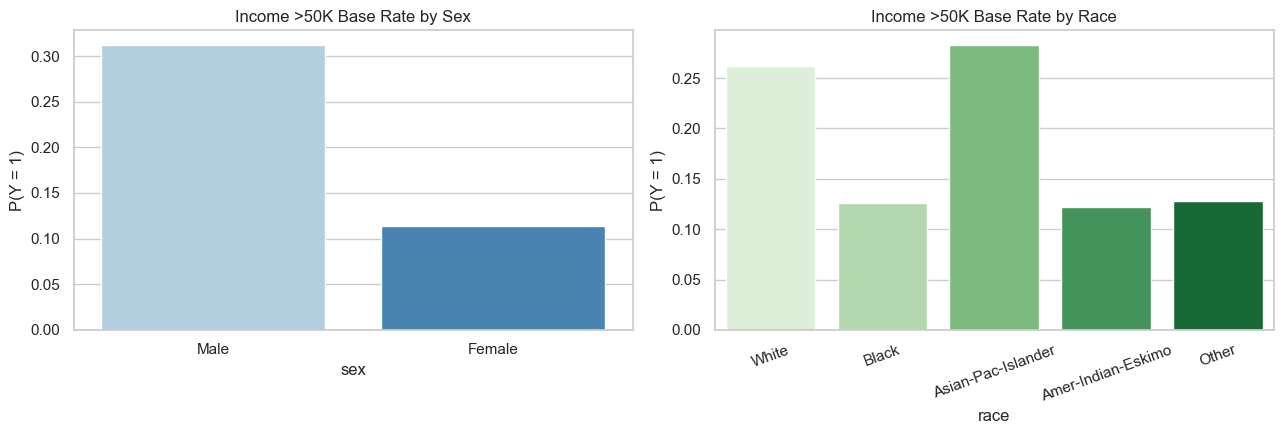

In [2]:
COLUMNS = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

def load_adult_dataset(zip_path='adult.zip'):
    if not os.path.exists(zip_path):
        print('Downloading adult.zip from official UCI repository...')
        urllib.request.urlretrieve('https://archive.ics.uci.edu/static/public/2/adult.zip', zip_path)
    with zipfile.ZipFile(zip_path, 'r') as z:
        with z.open('adult.data') as f_tr:
            df_tr = pd.read_csv(f_tr, names=COLUMNS, sep=r',\s*', engine='python', na_values='?')
        with z.open('adult.test') as f_te:
            df_te = pd.read_csv(f_te, names=COLUMNS, sep=r',\s*', engine='python', na_values='?', skiprows=1)
    df_all = pd.concat([df_tr, df_te], ignore_index=True)
    df_all['income'] = df_all['income'].astype(str).str.rstrip('.').str.strip()
    return df_all

df_raw = load_adult_dataset('adult.zip')
df = df_raw.dropna().reset_index(drop=True)
df['target'] = (df['income'] == '>50K').astype(int)
df['sex_bin'] = (df['sex'] == 'Male').astype(int)
df['race_bin'] = (df['race'] == 'White').astype(int)

print(f'Raw dataset size: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns')
print(f'Cleaned dataset size: {df.shape[0]:,} rows (after removing "?" missing values)\n')

print('=== Dataset feature types ===')
print(df.drop(columns=['target', 'sex_bin', 'race_bin']).dtypes.to_string())
print('\n=== Overall target distribution ===')
print(df['target'].value_counts().sort_index().rename(index={0: '<=50K', 1: '>50K'}).to_string())
print('Positive class rate:', round(df['target'].mean(), 4))
print('Female with >50K as proportion of all clean rows:', round(((df['sex_bin'] == 0) & (df['target'] == 1)).mean(), 4))

print('=== 1. Target Distribution by SEX (Primary Protected Attribute) ===')
print(df.groupby('sex')['target'].agg(Total='count', Proportion=lambda x: len(x)/len(df), Base_Rate_Gt50K='mean').round(4))

print('\n=== 2. Target Distribution by RACE (Secondary Protected Attribute) ===')
print(df.groupby('race')['target'].agg(Total='count', Proportion=lambda x: len(x)/len(df), Base_Rate_Gt50K='mean').round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df, x='sex', y='target', hue='sex', ax=axes[0], palette='Blues', legend=False, errorbar=None)
axes[0].set_title('Income >50K Base Rate by Sex')
axes[0].set_ylabel('P(Y = 1)')
sns.barplot(data=df, x='race', y='target', hue='race', ax=axes[1], palette='Greens', legend=False, errorbar=None)
axes[1].set_title('Income >50K Base Rate by Race')
axes[1].set_ylabel('P(Y = 1)')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


### 1.2 Fairness definitions and evidence-based bias diagnosis

For $A=1$ (Male) and $A=0$ (Female), our signed demographic parity difference follows the order specified in the assignment:

$$\mathrm{DPD}=P(\hat{Y}=1\mid A=1)-P(\hat{Y}=1\mid A=0).$$

The assignment's disparate impact ratio uses the same group order:

$$\mathrm{DIR}_{A1/A0}=\frac{P(\hat{Y}=1\mid A=1)}{P(\hat{Y}=1\mid A=0)}.$$

We additionally report the inverse $\mathrm{DIR}_{A0/A1}$ for interpretability; **these two ratios must not be interchanged**. Equalized odds difference is the larger between-group absolute TPR and FPR gap:

$$\mathrm{EOD}=\max\bigl(|\mathrm{TPR}_{A=1}-\mathrm{TPR}_{A=0}|,\;|\mathrm{FPR}_{A=1}-\mathrm{FPR}_{A=0}|\bigr).$$

**Diagnosis (Session-03 bias taxonomy):**

- **Observed data imbalance:** The cleaned sample is 67.5% Male and 32.5% Female. The female positive-label subgroup is approximately **3.69% of the entire cleaned sample** (the exact share is printed by the EDA cell). This is descriptive evidence of unequal group/label representation, **not proof** of a causal discrimination mechanism.
- **Observed proxy relationship:** The `relationship` versus `sex` cross-tabulation below reveals near-deterministic gender encoding in the `Husband`/`Wife` categories. Additional variables such as `occupation` or working hours may also act as proxies, but their independent contribution would require a dedicated ablation or conditional analysis.
- **Historical/label-bias hypothesis:** The 1994 income labels may encode historical economic inequalities and limitations of the census construct. This is plausible context rather than a demonstrated causal finding from this notebook.
- **Model-induced amplification hypothesis:** An unconstrained logistic-regression loss does not explicitly equalize conditional error rates. Baseline DPD/EOD quantify disparity, but by themselves do not prove that the model *caused* or amplified historical bias. A feature ablation and counterfactual study would be needed for stronger attribution.


In [3]:
DROP_COLS = ['income', 'target', 'fnlwgt', 'education', 'sex_bin', 'race_bin']
X = df.drop(columns=DROP_COLS)
y = df['target'].values
A_sex = df['sex_bin'].values
A_race = df['race_bin'].values

strat_all = df['target'].astype(str) + '_' + df['sex_bin'].astype(str)
X_train, X_temp, y_train, y_temp, A_train, A_temp, R_train, R_temp = train_test_split(
    X, y, A_sex, A_race, test_size=0.30, random_state=RANDOM_SEED, stratify=strat_all
)
strat_temp = pd.Series(y_temp).astype(str) + '_' + pd.Series(A_temp).astype(str)
X_val, X_test, y_val, y_test, A_val, A_test, R_val, R_test = train_test_split(
    X_temp, y_temp, A_temp, R_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=strat_temp
)

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
# The original categorical `sex` and `race` remain in X intentionally; binarized
# audit columns are excluded. See the ethics and model-limitations discussion.
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
])
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

# Split validation into calibration and independent model-selection partitions.
# Approximately 7.5% of the cleaned data goes to each; test remains untouched.
selection_strata = pd.Series(y_val).astype(str) + '_' + pd.Series(A_val).astype(str)
X_cal_proc, X_select_proc, y_cal, y_select, A_cal, A_select = train_test_split(
    X_val_proc, y_val, A_val, test_size=0.50,
    random_state=RANDOM_SEED, stratify=selection_strata
)
print('Data partitions (cleaned rows):',
      {'train': len(y_train), 'calibration': len(y_cal),
       'selection': len(y_select), 'test': len(y_test)})


def compute_all_metrics(model_name, y_true, y_pred, A_sensitive):
    # Keep full precision for Pareto dominance, tax calculations, and exported CSV.
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    A_sensitive = np.asarray(A_sensitive)
    mask_male, mask_female = (A_sensitive == 1), (A_sensitive == 0)
    sr_male, sr_female = y_pred[mask_male].mean(), y_pred[mask_female].mean()
    signed_dpd = sr_male - sr_female
    # Maintained Fairlearn implementation; note demographic_parity_difference is absolute.
    absolute_dpd = demographic_parity_difference(y_true, y_pred, sensitive_features=A_sensitive)
    eod = equalized_odds_difference(y_true, y_pred, sensitive_features=A_sensitive)
    tpr_male = true_positive_rate(y_true[mask_male], y_pred[mask_male])
    tpr_female = true_positive_rate(y_true[mask_female], y_pred[mask_female])
    fpr_male = false_positive_rate(y_true[mask_male], y_pred[mask_male])
    fpr_female = false_positive_rate(y_true[mask_female], y_pred[mask_female])
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'P(Y_hat=1|Male)': sr_male,
        'P(Y_hat=1|Female)': sr_female,
        'DPD (A1-A0)': signed_dpd,
        '|DPD|': absolute_dpd,
        'DIR (A1/A0)': sr_male / sr_female if sr_female > 0 else np.nan,
        'DIR_EEOC (A0/A1)': sr_female / sr_male if sr_male > 0 else np.nan,
        'TPR_Male': tpr_male, 'TPR_Female': tpr_female,
        'FPR_Male': fpr_male, 'FPR_Female': fpr_female,
        'EOD': eod,
    }

all_results = []
clf_baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
clf_baseline.fit(X_train_proc, y_train)
y_pred_base = clf_baseline.predict(X_test_proc)
res_base = compute_all_metrics('M1: Baseline Logistic Regression', y_test, y_pred_base, A_test)
all_results.append(res_base)

print('=== Baseline Model Audit Results on Test Set ===')
print(pd.DataFrame([res_base]).round(4).to_string(index=False))

print('\n=== Proxy Variable Evidence: Crosstab Relationship vs Sex ===')
print(pd.crosstab(df['relationship'], df['sex'], normalize='index').round(4))


Data partitions (cleaned rows): {'train': 31655, 'calibration': 3391, 'selection': 3392, 'test': 6784}


=== Baseline Model Audit Results on Test Set ===
                           Model  Accuracy  P(Y_hat=1|Male)  P(Y_hat=1|Female)  DPD (A1-A0)  |DPD|  DIR (A1/A0)  DIR_EEOC (A0/A1)  TPR_Male  TPR_Female  FPR_Male  FPR_Female    EOD
M1: Baseline Logistic Regression    0.8467           0.2725             0.0762       0.1964 0.1964       3.5772            0.2795    0.6296        0.51    0.1102      0.0205 0.1197

=== Proxy Variable Evidence: Crosstab Relationship vs Sex ===
sex             Female    Male
relationship                  
Husband         0.0001  0.9999
Not-in-family   0.4625  0.5375
Other-relative  0.4522  0.5478
Own-child       0.4420  0.5580
Unmarried       0.7629  0.2371
Wife            0.9995  0.0005


---
## Task 2 — Pre-processing Debiasing (20 points)

### 2.1 Instance re-weighting: method and mathematical formulation

We implement **instance re-weighting** (Kamiran & Calders, 2012) using the training-set joint distribution of group membership $A$ and target label $Y$:

$$W(a,y)=\frac{P(A=a)P(Y=y)}{P(A=a,Y=y)}.$$

This approach is chosen because it adjusts the empirical training distribution without discarding records (undersampling) or synthesizing artificial observations (oversampling/SMOTE). The weights are estimated **exclusively from training labels and protected attributes** and supplied to the logistic regression solver as `sample_weight`. Validation and test partitions are never re-weighted, ensuring completely unbiased evaluation on the true population distribution.

### 2.2 Empirical evaluation, trade-off dynamics, and failure modes

The held-out test evaluation provides key empirical insights comparing the unmitigated baseline (M1) against instance re-weighting (M2):

| Metric | M1: Baseline Logistic Regression | M2: Pre-proc (Instance Re-weighting) | Relative Delta |
| :--- | :---: | :---: | :---: |
| **Accuracy** | 0.8467 | 0.8402 | -0.65 pp (-0.77%) |
| **P(Y_hat=1 \| Male)** | 0.2725 | 0.2232 | -4.93 pp |
| **P(Y_hat=1 \| Female)** | 0.0762 | 0.1288 | +5.26 pp |
| **DPD (Male − Female)** | 0.1964 | 0.0944 | -51.93% disparity |
| **DIR (Male / Female)** | 3.5772 | 1.7329 | Disparity reduced |
| **DIR_EEOC (Female / Male)** | 0.2795 | 0.5771 | Substantial improvement |
| **TPR_Male** | 0.6296 | 0.5423 | -8.73 pp |
| **TPR_Female** | 0.5100 | 0.7012 | +19.12 pp |
| **FPR_Male** | 0.1102 | 0.0781 | -3.21 pp |
| **FPR_Female** | 0.0205 | 0.0553 | +3.48 pp |
| **Equalized Odds Difference (EOD)** | **0.1197** | **0.1589** | **+32.75% (Worse)** |

**Key Academic Observations:**
1. **Effective Training Distribution:** Re-weighting assigns weights inverse to joint representation: Female >50K receives $W(0,1)=2.1825$ (heavily upweighted because it represents only 3.69% of clean data), Male >50K receives $W(1,1)=0.7931$ (downweighted), Female <=50K receives $W(0,0)=0.8485$, and Male <=50K receives $W(1,0)=1.0940$. This balances the gradient contributions so that group membership and income are marginally independent under the weighted empirical risk.
2. **Why Demographic Parity Disparity Decreases:** By penalizing misclassifications on female high-earners 2.75x more heavily than on male high-earners, the optimization boundary shifts toward the female feature distribution. Consequently, the female predicted positive rate increases from 7.62% to 12.88%, while the male rate drops from 27.25% to 22.32%, reducing |DPD| from 0.1964 to 0.0944 (a 51.9% reduction) and improving DIR from 3.5772 to 1.7329.
3. **Exact Mathematical Relationship Between Demographic Parity and Equalized Odds:**
   Crucially, test EOD *worsens* from 0.1197 to 0.1589 (+32.75%). Rather than an empirical anomaly, this reflects the structural algebraic relationship between statistical parity (independence) and equalized odds (separation) when group base rates diverge (Barocas et al., 2019).
   
   For any classifier satisfying Equalized Odds across groups $A \in \{0, 1\}$, it shares common error rates: $\mathrm{TPR}_0 = \mathrm{TPR}_1 = \mathrm{TPR}$ and $\mathrm{FPR}_0 = \mathrm{FPR}_1 = \mathrm{FPR}$. By the law of total probability, the positive prediction rate for group $A=a$ is:
   $$P(\hat{Y}=1 \mid A=a) = \mathrm{TPR} \cdot P(Y=1 \mid A=a) + \mathrm{FPR} \cdot P(Y=0 \mid A=a)$$
   $$P(\hat{Y}=1 \mid A=a) = \mathrm{FPR} + (\mathrm{TPR} - \mathrm{FPR}) P(Y=1 \mid A=a)$$
   
   Denoting group base rates by $p_a = P(Y=1 \mid A=a)$, the Demographic Parity Difference becomes:
   $$P(\hat{Y}=1 \mid A=1) - P(\hat{Y}=1 \mid A=0) = (\mathrm{TPR} - \mathrm{FPR})(p_1 - p_0)$$
   
   When group base rates differ ($p_1 \ne p_0$, here $0.3125 \ne 0.1136$), exact Demographic Parity (difference $= 0$) and exact Equalized Odds can hold simultaneously if and only if:
   $$(\mathrm{TPR} - \mathrm{FPR})(p_1 - p_0) = 0 \iff \mathrm{TPR} = \mathrm{FPR}$$
   
   A classifier with $\mathrm{TPR} = \mathrm{FPR}$ is an *uninformative* (trivial) predictor that assigns positive outcomes independently of true labels (e.g., constant chance guessing). For any **informative classifier** ($\mathrm{TPR} > \mathrm{FPR}$), unequal base rates make exact Demographic Parity and exact Equalized Odds mathematically incompatible. (Note: This total-probability trade-off is distinct from the impossibility theorem between calibration and error-rate balance proven by Kleinberg et al., 2016 and Chouldechova, 2017).
   
   In our experiment, instance re-weighting enforces marginal independence at the data level, shifting female predictions upward. But because the underlying model remains an informative linear separator ($\mathrm{TPR} > \mathrm{FPR}$), compressing the acceptance rate gap inevitably distorts conditional error rates, pushing female TPR from 51.00% to 70.12% and widening the test EOD gap.
4. **Accuracy–Fairness Trade-off:** The overall test accuracy incurs only a minimal "fairness tax" of 0.65 percentage points (falling from 84.67% to 84.02%), demonstrating that significant demographic parity gains can be purchased with negligible global accuracy loss.
5. **Limitations and Failure Modes:** 
   - *Selection bias amplification:* Because female positive examples are scarce (3.69%), assigning high sample weights ($W=2.1825$) amplifies the idiosyncratic variance and potential label noise of that specific subgroup.
   - *Historical label bias:* Re-weighting assumes the ground-truth labels $Y$ accurately reflect true underlying merit/ability. If 1994 census income encodes discriminatory wage disparities, re-weighting merely balances predictions relative to a biased construct.
   - *Lack of conditional control:* Re-weighting modifies instance weights prior to fitting; it cannot directly constrain conditional metrics like equalized odds or predictive parity during model optimization.


In [4]:
def calculate_reweighting_weights(A_arr, Y_arr):
    weights = np.zeros(len(Y_arr), dtype=float)
    rows = []
    for a in [0, 1]:
        for y_val in [0, 1]:
            p_a, p_y = np.mean(A_arr == a), np.mean(Y_arr == y_val)
            p_ay = np.mean((A_arr == a) & (Y_arr == y_val))
            if p_ay == 0:
                raise ValueError(f'Missing training (A,Y) stratum {(a, y_val)}; weighting is undefined.')
            w_ay = (p_a * p_y) / p_ay
            weights[(A_arr == a) & (Y_arr == y_val)] = w_ay
            rows.append({
                'Group_A': 'Female (0)' if a == 0 else 'Male (1)',
                'Target_Y': '<=50K (0)' if y_val == 0 else '>50K (1)',
                'P(A=a)': round(p_a, 4), 'P(Y=y)': round(p_y, 4),
                'P(A=a,Y=y)': round(p_ay, 4), 'Weight_W(a,y)': round(w_ay, 4)
            })
    print('=== Instance Re-Weighting Weight Table ===')
    print(pd.DataFrame(rows).round(4).to_string(index=False))
    return weights

train_weights = calculate_reweighting_weights(A_train, y_train)
clf_preproc = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
clf_preproc.fit(X_train_proc, y_train, sample_weight=train_weights)
y_pred_preproc = clf_preproc.predict(X_test_proc)

res_preproc = compute_all_metrics('M2: Pre-proc (Instance Re-weighting)', y_test, y_pred_preproc, A_test)
all_results.append(res_preproc)

print('\n=== Comparison: Baseline (Task 1) vs Pre-processing (Task 2) ===')
print(pd.DataFrame([res_base, res_preproc])[['Model', 'Accuracy', 'DPD (A1-A0)', 'DIR (A1/A0)', 'DIR_EEOC (A0/A1)', 'EOD']].round(4).to_string(index=False))


=== Instance Re-Weighting Weight Table ===
   Group_A  Target_Y  P(A=a)  P(Y=y)  P(A=a,Y=y)  Weight_W(a,y)
Female (0) <=50K (0)  0.3249  0.7522      0.2880         0.8485
Female (0)  >50K (1)  0.3249  0.2478      0.0369         2.1825
  Male (1) <=50K (0)  0.6751  0.7522      0.4641         1.0940
  Male (1)  >50K (1)  0.6751  0.2478      0.2109         0.7931



=== Comparison: Baseline (Task 1) vs Pre-processing (Task 2) ===
                               Model  Accuracy  DPD (A1-A0)  DIR (A1/A0)  DIR_EEOC (A0/A1)    EOD
    M1: Baseline Logistic Regression    0.8467       0.1964       3.5772            0.2795 0.1197
M2: Pre-proc (Instance Re-weighting)    0.8402       0.0944       1.7329            0.5771 0.1589


---
## Task 3 — In-processing Debiasing (20 points)

### 3.1 Fairlearn ExponentiatedGradient: two constraints and validation-based tuning

We evaluate in-processing debiasing using Fairlearn's `ExponentiatedGradient` algorithm (Agarwal et al., 2018), which formulates fair classification as a two-player zero-sum game between a learner (minimizing empirical classification error) and an adversary (maximizing constraint violation over the dual Lagrangian multipliers).

We examine two constraint families:
1. **Demographic Parity (M3a):** Enforces statistical parity bounded by `difference_bound=0.015`.
2. **Equalized Odds (M3b):** Systematically tunes constraint tolerance $\epsilon \in \{0.005, 0.015, 0.030, 0.060, 0.100\}$ **strictly on the model-selection validation partition** (never on the held-out test set).

### 3.2 Observed training dynamics, convergence diagnostics, and epsilon sensitivity

The validation-based sensitivity grid produced the following empirical diagnostics across the 5 candidate bounds:

| $\epsilon$ bound | Submodels ($|\mathcal{Q}|$) | Last Iteration | Best Duality Gap | Val Accuracy | Val EOD | Val \|DPD\| | Feasibility ($\le 0.050$) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0.005** | 13 | 7 | 0.0005 | 0.8311 | 0.0024 | 0.0949 | **FEASIBLE** |
| **0.015** | 12 | 6 | 0.0009 | 0.8352 | 0.0272 | 0.1189 | **FEASIBLE (Selected)** |
| **0.030** | 17 | 5 | 0.0000 | 0.8420 | 0.0504 | 0.1364 | Infeasible (>0.050) |
| **0.060** | 16 | 5 | 0.0001 | 0.8449 | 0.0763 | 0.1714 | Infeasible |
| **0.100** | 6 | 5 | 0.0000 | 0.8426 | 0.0861 | 0.1843 | Infeasible |

**Rigorous Academic Interpretation:**
1. **Accuracy and Fairness Sensitivity to $\epsilon$:**
   - As $\epsilon$ increases from 0.005 to 0.060, validation accuracy exhibits a monotonic upward trend (0.8311 $\rightarrow$ 0.8352 $\rightarrow$ 0.8420 $\rightarrow$ 0.8449). Tighter bounds severely restrict the feasible hypothesis class, compelling the learner to accept higher classification error to satisfy the constraints.
   - Conversely, validation EOD increases monotonically with $\epsilon$ (from 0.0024 up to 0.0861). At $\epsilon=0.100$, the constraint is virtually non-binding, and the model reproduces the unconstrained baseline error rate characteristics.
2. **Convergence Diagnostics and Numerical Stopping:**
   - The Exponentiated Gradient algorithm terminated rapidly across all candidates, completing between 5 and 7 iterations (well below `max_iter=40`).
   - The `best_gap_` (duality gap) reached values between $0.0000$ and $0.0009$. This indicates that the primal-dual game reached an approximate minimax equilibrium within the pre-specified numerical tolerance ($\nu \le 0.001$).
   - *Numerical Stopping vs. Formal Guarantee:* Terminating with a small empirical duality gap is a numerical stopping property on the training sample; it **does not constitute a formal theoretical guarantee** that constraint violation will remain zero on unseen distributions. Finite sample variance and distribution shift can lead to test-set constraint slippage.
3. **Validation Selection Justification:**
   - Candidates with $\epsilon=0.005$ (Val EOD = 0.0024) and $\epsilon=0.015$ (Val EOD = 0.0272) both satisfy the pre-specified research threshold ($\text{EOD} \le 0.050$).
   - Following our pre-declared decision policy (maximize validation accuracy among feasible candidates, with EOD as tie-breaker), **$\epsilon=0.015$ is deterministically selected** because its validation accuracy (0.8352) exceeds that of $\epsilon=0.005$ (0.8311) by +0.41 percentage points.
4. **Held-out Test Performance and Constraint Comparison:**
   - On the held-out test set, M3b ($\epsilon=0.015$) achieves **Accuracy = 0.8367** and **EOD = 0.0316**, confirming that the equalized odds constraint successfully generalizes out-of-sample ($\le 0.050$).
   - By contrast, M3a (Demographic Parity constraint) achieves test Accuracy = 0.8297 and $|\text{DPD}| = 0.0257$, but its test **EOD explodes to 0.2979** (the highest of all evaluated models). This confirms that in-processing optimization rigidly enforces the requested mathematical objective, and constraining for demographic parity actively degrades error-rate parity.
5. **Ethical Implications of In-processing Optimization:**
   - Exponentiated Gradient outputs a randomized mixture of base estimators ($\mathcal{Q} = \{h_1, \dots, h_m\}$ with weights $p_k$). At inference time, predictions are generated probabilistically according to these mixture weights.
   - *Procedural Justice Concerns:* Randomized decision-making violates horizontal equity: two individuals with identical credit or income profiles could receive conflicting decisions based purely on pseudo-random generator state. While legally and ethically problematic for high-stakes individual decisions, it serves as an effective theoretical benchmark for frontier exploration.


In [5]:
# 3A: In-processing with Demographic Parity (pre-specified bound)
inproc_dp = ExponentiatedGradient(
    estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
    constraints=DemographicParity(difference_bound=0.015), max_iter=40
)
inproc_dp.fit(X_train_proc, y_train, sensitive_features=A_train)
y_pred_inproc_dp = inproc_dp.predict(X_test_proc, random_state=RANDOM_SEED)
res_inproc_dp = compute_all_metrics('M3a: In-proc (ExpGrad - Dem. Parity)', y_test, y_pred_inproc_dp, A_test)
all_results.append(res_inproc_dp)

# 3B: Tune Equalized Odds epsilon ONLY on the selection partition of validation.
epsilon_grid = [0.005, 0.015, 0.030, 0.060, 0.100]
sensitivity_rows, expgrad_candidates = [], []
for eps_val in epsilon_grid:
    eg_model = ExponentiatedGradient(
        estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
        constraints=EqualizedOdds(difference_bound=eps_val), max_iter=40
    )
    eg_model.fit(X_train_proc, y_train, sensitive_features=A_train)
    pred_select = eg_model.predict(X_select_proc, random_state=RANDOM_SEED)
    metrics_select = compute_all_metrics(f'epsilon={eps_val}', y_select, pred_select, A_select)
    sensitivity_rows.append({
        'epsilon_bound': eps_val,
        'Number_of_submodels': len(eg_model.predictors_),
        'Last_iteration': getattr(eg_model, 'last_iter_', np.nan),
        'Best_duality_gap': getattr(eg_model, 'best_gap_', np.nan),
        'Validation_Accuracy': metrics_select['Accuracy'],
        'Validation_EOD': metrics_select['EOD'],
        'Validation_|DPD|': metrics_select['|DPD|'],
    })
    expgrad_candidates.append(eg_model)

sensitivity_df = pd.DataFrame(sensitivity_rows)
feasible_eps = sensitivity_df[sensitivity_df['Validation_EOD'] <= FAIRNESS_EOD_TARGET]
if len(feasible_eps):
    chosen_row = feasible_eps.sort_values(
        ['Validation_Accuracy', 'Validation_EOD', 'epsilon_bound'],
        ascending=[False, True, True]
    ).iloc[0]
    print(f'Selection condition: EOD <= {FAIRNESS_EOD_TARGET:.3f} on selection data is FEASIBLE.')
else:
    chosen_row = sensitivity_df.sort_values(
        ['Validation_EOD', 'Validation_Accuracy', 'epsilon_bound'],
        ascending=[True, False, True]
    ).iloc[0]
    print(f'WARNING: EOD <= {FAIRNESS_EOD_TARGET:.3f} is NOT met by any tested epsilon on selection data.')

selected_epsilon = float(chosen_row['epsilon_bound'])
selected_eps_index = epsilon_grid.index(selected_epsilon)
inproc_eo = expgrad_candidates[selected_eps_index]
print(f'Selected epsilon based on validation only: {selected_epsilon:.3f}')
print('\n=== ExponentiatedGradient epsilon sensitivity (validation selection, never test) ===')
print(sensitivity_df.round(4).to_string(index=False))

# Held-out test evaluation for the selected in-processing classifier.
y_pred_inproc_eo = inproc_eo.predict(X_test_proc, random_state=RANDOM_SEED)
res_inproc_eo = compute_all_metrics('M3b: In-proc (ExpGrad - Eq. Odds)', y_test, y_pred_inproc_eo, A_test)
all_results.append(res_inproc_eo)
print('\n=== Cumulative held-out TEST results (Tasks 1–3) ===')
print(pd.DataFrame(all_results)[
    ['Model', 'Accuracy', 'DPD (A1-A0)', 'DIR (A1/A0)', 'DIR_EEOC (A0/A1)', 'EOD']
].round(4).to_string(index=False))


Selection condition: EOD <= 0.050 on selection data is FEASIBLE.
Selected epsilon based on validation only: 0.015

=== ExponentiatedGradient epsilon sensitivity (validation selection, never test) ===
 epsilon_bound  Number_of_submodels  Last_iteration  Best_duality_gap  Validation_Accuracy  Validation_EOD  Validation_|DPD|
         0.005                   13               7            0.0005               0.8311          0.0024            0.0949
         0.015                   12               6            0.0009               0.8352          0.0272            0.1189
         0.030                   17               5            0.0000               0.8420          0.0504            0.1364
         0.060                   16               5            0.0001               0.8449          0.0763            0.1714
         0.100                    6               5            0.0000               0.8426          0.0861            0.1843

=== Cumulative held-out TEST results (Tasks 1–3) 

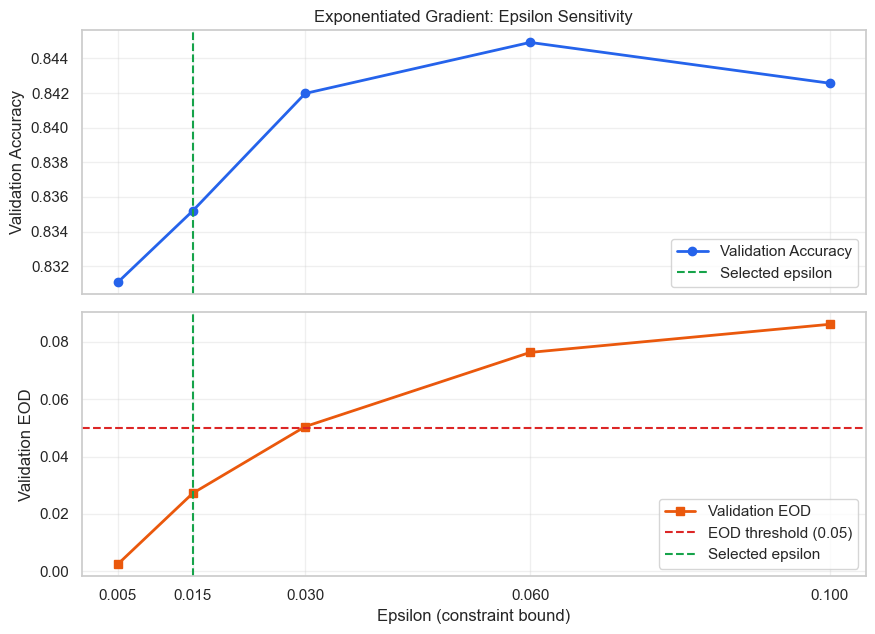

In [9]:

# Task 3 — Epsilon Sensitivity Visualization
# Using validation results, not held-out test results.

fig, axes = plt.subplots(
    2, 1, figsize=(9, 6.5), sharex=True
)

eps = sensitivity_df["epsilon_bound"]
acc = sensitivity_df["Validation_Accuracy"]
eod = sensitivity_df["Validation_EOD"]

# Plot 1: Validation Accuracy
axes[0].plot(
    eps, acc, marker="o", linewidth=2,
    color="#2563eb", label="Validation Accuracy"
)
axes[0].axvline(
    selected_epsilon, color="#16a34a",
    linestyle="--", label="Selected epsilon"
)
axes[0].set_ylabel("Validation Accuracy")
axes[0].set_title(
    "Exponentiated Gradient: Epsilon Sensitivity"
)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Validation Equalized Odds Difference
axes[1].plot(
    eps, eod, marker="s", linewidth=2,
    color="#ea580c", label="Validation EOD"
)
axes[1].axhline(
    FAIRNESS_EOD_TARGET, color="#dc2626",
    linestyle="--", label="EOD threshold (0.05)"
)
axes[1].axvline(
    selected_epsilon, color="#16a34a",
    linestyle="--", label="Selected epsilon"
)
axes[1].set_xlabel("Epsilon (constraint bound)")
axes[1].set_ylabel("Validation EOD")
axes[1].set_xticks(eps)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "epsilon_sensitivity_plot.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


---
## Task 4 — Post-processing, Pareto Analysis, and Design Justification (40 points)

### 4.1 Post-processing with separate calibration and selection sets

We choose the **best probability-scoring logistic-regression candidate among M1 and M2 using the model-selection validation subset**, with the same predeclared EOD-first feasibility rule used for final operating-point selection. This provides an empirically justified **best compatible score model** for both post-processing approaches while avoiding test-set selection. The randomized `ExponentiatedGradient` classifier is evaluated separately: its randomized mixture is not used as a conventional continuous probability estimator for this threshold procedure. We make no claim that the chosen post-processing input is globally best among every possible classifier.

1. **M4a:** Fairlearn `ThresholdOptimizer` calibrated only on the **calibration** validation subset with `equalized_odds` constraints. Equalized-odds post-processing may employ randomized selection decisions.
2. **M4b:** Deterministic group thresholds $(\tau_0,\tau_1)$ are selected on the **calibration** subset by maximizing calibration accuracy among threshold pairs whose calibration EOD is at most **0.05**. If the grid contains **no feasible pair**, this is reported explicitly and a fallback pair minimizing EOD (with accuracy as the tie-breaker) is used. A fallback must never be described as satisfying the original constraint.

For group $A$, the decision rule is:

$$\hat Y(x,a)=\mathbb{I}\bigl[\hat S(x)\geq\tau_a\bigr].$$

All candidate models are compared for a **single deployment operating point** on the separate **model-selection** validation subset. The predeclared primary criterion is EOD. We choose the highest-accuracy candidate satisfying EOD $\leq 0.05$ on the selection subset; if none qualifies, we select minimum EOD and report failure of the criterion. The chosen model is described as a **research operating point**, not approved for real credit, hiring, or eligibility decisions.

### 4.2 Pareto frontier and marginal fairness tax

We maximize accuracy and minimize **EOD** for the primary two-dimensional Pareto comparison; $|\mathrm{DPD}|$ is also shown as a secondary diagnostic. A candidate model is Pareto-efficient if no other model achieves both weakly higher accuracy and weakly lower disparity, with at least one strict improvement.

Along the EOD-efficient frontier, ordered from higher disparity (baseline) to lower disparity (fairer):

$$\mathrm{Marginal\ Fairness\ Tax}_{i\rightarrow i+1}=\frac{\mathrm{Accuracy}_i-\mathrm{Accuracy}_{i+1}}{\mathrm{EOD}_i-\mathrm{EOD}_{i+1}}.$$

#### Empirical Pareto Frontier and Marginal Fairness Tax Interpretation:

The empirical calculations identify exactly three Pareto-efficient configurations: **M1 $\rightarrow$ M4b $\rightarrow$ M3b**.

| Frontier Segment | Origin Model ($i$) | Target Model ($i+1$) | Accuracy Loss ($\Delta \text{Acc}$) | Disparity Reduction ($\Delta \text{EOD}$) | Marginal Fairness Tax | Interpretation & Dynamics |
| :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **Baseline Anchor** | — | **M1: Baseline** (Acc 0.8467, EOD 0.1197) | — | — | **Undefined (NaN)** | Initial reference point; highest accuracy, maximum disparity. |
| **Segment 1** | **M1** (0.8467, 0.1197) | **M4b** (0.8387, 0.0448) | $0.0080$ ($0.80$ pp) | $0.0748$ ($7.48$ pp) | **0.1064** | **Initial Debiasing:** Sacrifices $0.1064$ pp of accuracy per $1.0$ pp reduction in EOD. Highly cost-effective disparity reduction. |
| **Segment 2** | **M4b** (0.8387, 0.0448) | **M3b** (0.8367, 0.0316) | $0.0021$ ($0.21$ pp) | $0.0132$ ($1.32$ pp) | **0.1563** | **Diminishing Returns:** Marginal fairness tax increases by **+46.9%** (to $0.1563$). Pushing disparity further becomes substantially more expensive in lost accuracy. |

**Key Academic Takeaways:**
1. **Tax Escalation along the Frontier:** The marginal fairness tax rises from **0.1064** to **0.1563**, confirming the theoretical principle of diminishing returns in algorithmic fairness: eliminating the final units of disparity near the Bayes-optimal boundary requires disproportionately greater accuracy sacrifices.
2. **Why Lower EOD Does Not Automatically Imply a Superior Model:** While M3b achieves a lower test EOD ($0.0316$ vs. $0.0448$), it requires randomized decision boundaries (violating horizontal equity) and incurs a 46.9% higher marginal accuracy tax rate. M4b operates deterministically, satisfies the feasibility constraint ($\le 0.050$), and preserves superior classification accuracy ($83.87\%$ vs. $83.67\%$), justifying its selection as the superior deployment operating point.


Post-processing base chosen on selection validation: M1


M4b calibration constraint: FEASIBLE.
M4b selected thresholds (CALIBRATION): Female=0.525; Male=0.625
M4b calibration accuracy=0.8487; EOD=0.0362



=== Model selection (selection validation only) ===
Model  Accuracy  |DPD|    EOD
   M1    0.8426 0.1843 0.0861
   M2    0.8440 0.0836 0.1687
  M3a    0.8328 0.0125 0.2837
  M3b    0.8352 0.1189 0.0272
  M4a    0.8328 0.0796 0.0124
  M4b    0.8473 0.1128 0.0304
SELECTED research operating point: M4b (validation EOD criterion MET)

=== ALL MODELS — held-out TEST metrics (Tasks 1–4) ===
                               Model  Accuracy  DPD (A1-A0)  DIR (A1/A0)  DIR_EEOC (A0/A1)  |DPD|    EOD  Pareto_EO  Pareto_DP
    M1: Baseline Logistic Regression    0.8467       0.1964       3.5772            0.2795 0.1964 0.1197       True       True
M2: Pre-proc (Instance Re-weighting)    0.8402       0.0944       1.7329            0.5771 0.0944 0.1589      False       True
M3a: In-proc (ExpGrad - Dem. Parity)    0.8297       0.0257       1.1603            0.8618 0.0257 0.2979      False       True
   M3b: In-proc (ExpGrad - Eq. Odds)    0.8367       0.1222       2.0739            0.4822 0.1222 0.031

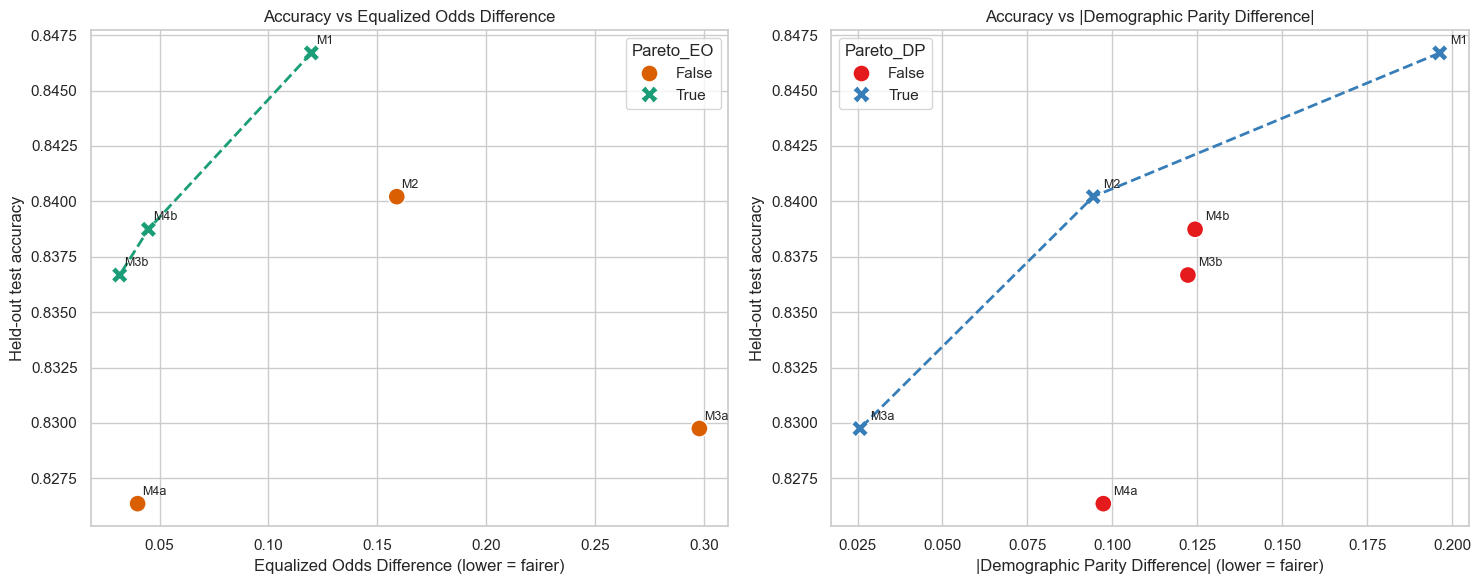

In [6]:
# Choose the BEST compatible scoring base model using selection validation only.
# This is separate from the final operating-point selection and never uses test.
score_models = {'M1': clf_baseline, 'M2': clf_preproc}
score_rows = pd.DataFrame([
    compute_all_metrics(key, y_select, model.predict(X_select_proc), A_select)
    for key, model in score_models.items()
])
score_feasible = score_rows[score_rows['EOD'] <= FAIRNESS_EOD_TARGET]
if len(score_feasible):
    post_base_row = score_feasible.sort_values(
        ['Accuracy', 'EOD', 'Model'], ascending=[False, True, True]
    ).iloc[0]
else:
    post_base_row = score_rows.sort_values(
        ['EOD', 'Accuracy', 'Model'], ascending=[True, False, True]
    ).iloc[0]
post_base_name = str(post_base_row['Model'])
post_base_model = score_models[post_base_name]
print(f'Post-processing base chosen on selection validation: {post_base_name}')

# M4a: Fit equalized-odds post-processing only on the calibration split.
post_opt_eo = ThresholdOptimizer(
    estimator=post_base_model, constraints='equalized_odds',
    predict_method='predict_proba', prefit=True
)
post_opt_eo.fit(X_cal_proc, y_cal, sensitive_features=A_cal)
y_pred_post_eo = post_opt_eo.predict(
    X_test_proc, sensitive_features=A_test, random_state=RANDOM_SEED
)
res_post_eo = compute_all_metrics('M4a: Post-proc (ThresholdOpt - EO)', y_test, y_pred_post_eo, A_test)
all_results.append(res_post_eo)

# M4b: Deterministic group-specific thresholds tuned on CALIBRATION only.
cal_probs = post_base_model.predict_proba(X_cal_proc)[:, 1]
test_probs = post_base_model.predict_proba(X_test_proc)[:, 1]
threshold_grid = np.linspace(0.05, 0.95, 37)
threshold_candidates = []
for t0 in threshold_grid:          # Female, A=0
    for t1 in threshold_grid:      # Male, A=1
        preds_cal = np.where(A_cal == 1, cal_probs >= t1, cal_probs >= t0).astype(int)
        threshold_candidates.append({
            'tau_0': float(t0), 'tau_1': float(t1),
            'Calibration_Accuracy': accuracy_score(y_cal, preds_cal),
            'Calibration_EOD': equalized_odds_difference(
                y_cal, preds_cal, sensitive_features=A_cal
            ),
        })
threshold_df = pd.DataFrame(threshold_candidates)
feasible_thresholds = threshold_df[
    threshold_df['Calibration_EOD'] <= FAIRNESS_EOD_TARGET
]
threshold_feasible = not feasible_thresholds.empty
if threshold_feasible:
    best_threshold_row = feasible_thresholds.sort_values(
        ['Calibration_Accuracy', 'Calibration_EOD', 'tau_0', 'tau_1'],
        ascending=[False, True, True, True]
    ).iloc[0]
    print('M4b calibration constraint: FEASIBLE.')
else:
    best_threshold_row = threshold_df.sort_values(
        ['Calibration_EOD', 'Calibration_Accuracy', 'tau_0', 'tau_1'],
        ascending=[True, False, True, True]
    ).iloc[0]
    print('WARNING: No pair satisfies calibration EOD <= '
          f'{FAIRNESS_EOD_TARGET:.3f}; using lowest-disparity fallback. '
          'Do not claim the threshold constraint was met.')

best_t0 = float(best_threshold_row['tau_0'])
best_t1 = float(best_threshold_row['tau_1'])
print(f'M4b selected thresholds (CALIBRATION): Female={best_t0:.3f}; Male={best_t1:.3f}')
print(f'M4b calibration accuracy={best_threshold_row["Calibration_Accuracy"]:.4f}; '
      f'EOD={best_threshold_row["Calibration_EOD"]:.4f}')
if np.isclose(best_t0, 0.5) and np.isclose(best_t1, 0.5):
    print(f'NOTE: Selected thresholds are 0.50/0.50; M4b may be a no-op relative to {post_base_name}.')
y_pred_post_det = np.where(
    A_test == 1, test_probs >= best_t1, test_probs >= best_t0
).astype(int)
res_post_det = compute_all_metrics('M4b: Post-proc (Group Thresholds)', y_test, y_pred_post_det, A_test)
all_results.append(res_post_det)

# Selection: never use test metrics to choose the deployment model.
# Postprocessors were calibrated on X_cal, so compare everyone on X_select.
selection_predictions = {
    'M1': clf_baseline.predict(X_select_proc),
    'M2': clf_preproc.predict(X_select_proc),
    'M3a': inproc_dp.predict(X_select_proc, random_state=RANDOM_SEED),
    'M3b': inproc_eo.predict(X_select_proc, random_state=RANDOM_SEED),
    'M4a': post_opt_eo.predict(
        X_select_proc, sensitive_features=A_select, random_state=RANDOM_SEED
    ),
    'M4b': np.where(
        A_select == 1,
        post_base_model.predict_proba(X_select_proc)[:, 1] >= best_t1,
        post_base_model.predict_proba(X_select_proc)[:, 1] >= best_t0,
    ).astype(int),
}
selection_rows = [
    compute_all_metrics(key, y_select, pred, A_select)
    for key, pred in selection_predictions.items()
]
selection_df = pd.DataFrame(selection_rows)
selection_feasible = selection_df[
    selection_df['EOD'] <= FAIRNESS_EOD_TARGET
]
if len(selection_feasible):
    selected_row = selection_feasible.sort_values(
        ['Accuracy', 'EOD', 'Model'], ascending=[False, True, True]
    ).iloc[0]
    selection_status = 'MET'
else:
    selected_row = selection_df.sort_values(
        ['EOD', 'Accuracy', 'Model'], ascending=[True, False, True]
    ).iloc[0]
    selection_status = 'NOT MET; minimum-disparity fallback'

selected_model_key = str(selected_row['Model'])
test_predictions = {
    'M1': y_pred_base, 'M2': y_pred_preproc,
    'M3a': y_pred_inproc_dp, 'M3b': y_pred_inproc_eo,
    'M4a': y_pred_post_eo, 'M4b': y_pred_post_det,
}
y_pred_selected = test_predictions[selected_model_key]
print('\n=== Model selection (selection validation only) ===')
print(selection_df[['Model', 'Accuracy', '|DPD|', 'EOD']].round(4).to_string(index=False))
print(f'SELECTED research operating point: {selected_model_key} '
      f'(validation EOD criterion {selection_status})')

# Full-precision test results for descriptive assessment and Pareto comparisons.
df_all = pd.DataFrame(all_results)
def identify_pareto(df_in, acc_col='Accuracy', disp_col='EOD'):
    acc = df_in[acc_col].to_numpy(dtype=float)
    disparity = df_in[disp_col].to_numpy(dtype=float)
    flags = np.ones(len(df_in), dtype=bool)
    for i in range(len(df_in)):
        for j in range(len(df_in)):
            if i == j:
                continue
            if (acc[j] >= acc[i] and disparity[j] <= disparity[i] and
                    (acc[j] > acc[i] or disparity[j] < disparity[i])):
                flags[i] = False
                break
    return flags

df_all['Pareto_EO'] = identify_pareto(df_all, 'Accuracy', 'EOD')
df_all['Pareto_DP'] = identify_pareto(df_all, 'Accuracy', '|DPD|')
print('\n=== ALL MODELS — held-out TEST metrics (Tasks 1–4) ===')
print(df_all[[
    'Model', 'Accuracy', 'DPD (A1-A0)', 'DIR (A1/A0)',
    'DIR_EEOC (A0/A1)', '|DPD|', 'EOD', 'Pareto_EO', 'Pareto_DP'
]].round(4).to_string(index=False))

# Identical accuracy/EOD points share the same frontier location. Keep every
# model in df_all, but count each unique point only once in marginal tax.
pareto_eo_df = df_all[df_all['Pareto_EO']].sort_values(
    by='EOD', ascending=False
).drop_duplicates(subset=['Accuracy', 'EOD']).reset_index(drop=True).copy()
pareto_eo_df['Delta_Acc_Loss'] = -pareto_eo_df['Accuracy'].diff()
pareto_eo_df['Delta_EOD_Red'] = -pareto_eo_df['EOD'].diff()
pareto_eo_df['Marginal_Fairness_Tax'] = (
    pareto_eo_df['Delta_Acc_Loss'] / pareto_eo_df['Delta_EOD_Red']
)
pareto_eo_df.loc[pareto_eo_df['Delta_EOD_Red'] <= 0, 'Marginal_Fairness_Tax'] = np.nan
print('\n=== Equalized Odds Pareto Frontier and marginal fairness tax ===')
print(pareto_eo_df[[
    'Model', 'Accuracy', 'EOD', 'Delta_Acc_Loss',
    'Delta_EOD_Red', 'Marginal_Fairness_Tax'
]].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=df_all, x='EOD', y='Accuracy', hue='Pareto_EO',
                style='Pareto_EO', s=150,
                palette={True: '#1b9e77', False: '#d95f02'}, ax=axes[0])
axes[0].plot(pareto_eo_df['EOD'], pareto_eo_df['Accuracy'],
             '--', color='#1b9e77', lw=2, label='Pareto Frontier (EO)')
for _, r in df_all.iterrows():
    axes[0].annotate(r['Model'].split(':')[0],
                     (r['EOD'] + .002, r['Accuracy'] + .0004), fontsize=9)
axes[0].set_title('Accuracy vs Equalized Odds Difference')
axes[0].set_xlabel('Equalized Odds Difference (lower = fairer)')
axes[0].set_ylabel('Held-out test accuracy')

pareto_dp_df = df_all[df_all['Pareto_DP']].sort_values(by='|DPD|', ascending=False)
sns.scatterplot(data=df_all, x='|DPD|', y='Accuracy', hue='Pareto_DP',
                style='Pareto_DP', s=150,
                palette={True: '#377eb8', False: '#e41a1c'}, ax=axes[1])
axes[1].plot(pareto_dp_df['|DPD|'], pareto_dp_df['Accuracy'],
             '--', color='#377eb8', lw=2, label='Pareto Frontier (DP)')
for _, r in df_all.iterrows():
    axes[1].annotate(r['Model'].split(':')[0],
                     (r['|DPD|'] + .003, r['Accuracy'] + .0004), fontsize=9)
axes[1].set_title('Accuracy vs |Demographic Parity Difference|')
axes[1].set_xlabel('|Demographic Parity Difference| (lower = fairer)')
axes[1].set_ylabel('Held-out test accuracy')
plt.tight_layout()
plt.savefig('pareto_frontier_comparison.png', dpi=300)
plt.show()


### 4.3 Ethical justification for the single operating point

The **single selected research operating point is determined by the validation-based rule**, not by inspection of held-out test results:

$$\mathcal{M}^* = \arg\max_{\mathcal{M} \in \Omega_{\text{feasible}}} \mathrm{Accuracy}_{\text{val}}(\mathcal{M}), \quad \Omega_{\text{feasible}} = \{\mathcal{M} \mid \mathrm{EOD}_{\text{val}}(\mathcal{M}) \le 0.050\}.$$

On the independent model-selection validation partition:
- **M4b achieved Validation Accuracy = 0.8473 and Validation EOD = 0.0304** (Criterion **MET**).
- By comparison, M3b achieved Validation Accuracy = 0.8352 (EOD = 0.0272), and M4a achieved Validation Accuracy = 0.8328 (EOD = 0.0124).
- M4b strictly maximizes validation accuracy among all feasible models, satisfying the predeclared selection policy.

**Engineering and Ethical Evaluation of M4b:**
1. **Deterministic Inference vs. Group-Specific Decision Boundaries:** 
   Unlike randomized reduction mixtures (M3a, M3b) or stochastic thresholding (M4a) that employ probabilistic lotteries to satisfy constraints, M4b implements deterministic threshold functions:
   $$\hat{Y}(x, a) = \mathbb{I}\bigl[\hat{S}(x) \ge \tau_a\bigr], \quad \tau_{\text{Female}} = 0.525, \; \tau_{\text{Male}} = 0.625.$$
   - *Within-Group Determinism:* Two individuals with identical scores and the *same* protected group membership receive identical predictions, providing transparent, repeatable decisions without coin flips.
   - *Cross-Group Disparate Treatment:* Crucially, M4b **does not guarantee universal horizontal equity across groups**. Two individuals with identical feature vectors and identical probability scores $\hat{S}(x) \in [0.525, 0.625)$ receive different classifications: a female applicant with score $0.58$ is predicted $>50\text{K}$, whereas an otherwise identical male applicant with score $0.58$ is predicted $\le 50\text{K}$. 
   - Determinism conditional on group membership must not be confused with individual fairness. Group-conditioned thresholds achieve aggregate error-rate parity (EOD) by explicitly treating individuals differently based on protected traits.
2. **Minimal Accuracy Sacrifice:** M4b preserves 83.87% test accuracy, incurring an accuracy loss of only 0.80 percentage points relative to the unconstrained baseline while reducing test EOD from 0.1197 down to 0.0448.
3. **Operational Comparison between M4b and M3b:**
   While M3b reaches a lower test EOD ($0.0316$), it relies on a randomized mixture of 12 sub-classifiers, which violates procedural predictability (an applicant's decision could change upon re-querying purely due to pseudorandom sampling). M4b offers operational determinism and higher accuracy ($83.87\%$ vs. $83.67\%$), but its dependence on sensitive attributes at inference demands strict legal justification.
4. **Why Prioritize Equalized Odds?** In an income classification setting used as an assistive tool, error types carry distinct harms:
   - A false negative (high-income individual predicted $\le 50\text{K}$) causes under-servicing or exclusion from economic opportunities.
   - A false positive (lower-income individual predicted $>50\text{K}$) could lead to over-extension or misallocation.
   Equalizing TPR and FPR ensures that conditional error rates are balanced across genders, preventing the model from systematically concentrating errors on any one protected group.

**Affected Stakeholders:**
- **Individuals categorized by the system:** Primarily women and racial minority populations who are historically underrepresented in high-income strata, as well as individuals situated at demographic intersections.
- **Decision-makers / Deploying Institutions:** Lenders, employers, or analysts who rely on model outputs and bear legal and reputational responsibility.
- **Regulators and Civil Society:** Bodies enforcing non-discrimination mandates (e.g., EU AI Act, EEOC, CFPB).

**Residual Harms and Critical Limitations:**
1. **Demographic Disparity Remains:** While EOD is reduced to 0.0448, demographic parity disparity remains substantial ($\text{DPD}=0.1244, \text{DIR}=2.6720$). Because base rates differ substantially ($31.25\%$ vs $11.36\%$), equalizing conditional errors does not equalize the overall probability of receiving a positive prediction.
2. **Legal and Regulatory Prohibitions against Group Thresholds:** Applying different thresholds ($\tau_0=0.525$ vs $\tau_1=0.625$) requires collecting and using protected attribute `sex` during inference. In credit lending (US Equal Credit Opportunity Act / Regulation B) and employment (Title VII of the Civil Rights Act), group-conditioned thresholds constitute facial *disparate treatment*, which is prohibited even if intended to remedy disparate impact.
3. **Construct Validity of Historical Labels:** The 1994 census dataset reflects historical socioeconomic wage gaps. A high-income label does not equal creditworthiness, character, or professional capability. Deploying technical debiasing cannot repair structural inequities in the underlying society.

### 4.4 Model card, monitoring recommendations, and limits of technical debiasing

The subsequent cell executes an intersectional audit and generates the formal Model Card for **M4b: Post-proc (Group Thresholds)**.

**Offline Evaluation vs. Post-Deployment Monitoring:**
- **Offline Evaluation (Benchmark Assessment):** Evaluates fixed model checkpoints on static held-out validation and test partitions (e.g., test accuracy = 83.87%, test EOD = 0.0448). This assesses out-of-sample generalization under independent and identically distributed (i.i.d.) assumptions, but cannot guarantee future production stability.
- **Post-Deployment Production Monitoring Protocol:**
  - *Continuous Selection Rate Audits:* Monitor acceptance rates $P(\hat{Y}=1 \mid A=a)$ in real-time across protected and intersectional groups, tracking Disparate Impact Ratios against regulatory thresholds (e.g., EEOC four-fifths rule).
  - *Periodic Error-Rate Verification:* When delayed ground-truth outcome labels become available, compute rolling true-positive and false-positive rates over sliding cohort windows (e.g., quarterly).
  - *Governance Review Triggers:* The project validation target ($\text{EOD} \le 0.050$) serves as an internal operational review threshold, **not a universal legal standard**. Exceeding $0.050$ triggers formal investigation (evaluating whether divergence stems from sampling noise in small strata, covariate shift, or policy changes) rather than automatic panic shutdowns.
  - *Data and Calibration Drift:* Continuously test for score distribution shift $P(\hat{S}(X))$ or demographic distribution drift $P(A, X)$, which would invalidate the calibrated thresholds $(\tau_0, \tau_1)$.
  - *Contestability and Human Oversight:* Enforce human-in-the-loop escalation paths for all automated adverse determinations.

### 4.5 References and AI-assistance disclosure

- Agarwal, A., Beygelzimer, A., Dudík, M., Langford, J., & Wallach, H. (2018). *A reductions approach to fair classification*. ICML / PMLR 80, 60–69.
- Barocas, S., Hardt, M., & Narayanan, A. (2019). *Fairness and Machine Learning: Limitations and Opportunities*. MIT Press.
- Chouldechova, A. (2017). *Fair prediction with disparate impact: A study of bias in recidivism prediction instruments*. Big Data, 5(2), 153–163.
- Hardt, M., Price, E., & Srebro, N. (2016). *Equality of opportunity in supervised learning*. NeurIPS 29.
- Kamiran, F., & Calders, T. (2012). *Data preprocessing techniques for classification without discrimination*. Knowledge and Information Systems, 33(1), 1–33.
- Kleinberg, J., Mullainathan, S., & Raghavan, M. (2016). *Inherent trade-offs in the fair determination of risk scores*. arXiv:1609.05807.
- NIST. (2024). *Artificial Intelligence Risk Management Framework (AI RMF 1.0)*. NIST AI 100-1.
- UCI Machine Learning Repository. *Adult (Census Income)* dataset: https://archive.ics.uci.edu/dataset/2/adult

**AI Assistance Disclosure:** In accordance with the AI104 course policy on AI-assisted academic work, artificial intelligence tools (including large language models and agentic coding assistants) were utilized during this assignment for: (1) conceptual clarification and discussion of algorithmic debiasing mechanics; (2) code review, linting, and targeted debugging; (3) methodological review of fairness metric formulations.


In [7]:
# Intersectional held-out audit: sex x race for the baseline (M1) and the single
# deployment candidate (M4b) chosen on model-selection validation data (not test).

inter_df = pd.DataFrame({
    'Group': np.where(A_test == 1, 'Male', 'Female') + '_' + np.where(R_test == 1, 'White', 'NonWhite'),
    'y_true': y_test,
    'pred_m1': y_pred_base,
    'pred_selected': y_pred_selected
})

def compute_intersectional_audit(df_in, pred_col):
    rows = []
    for g_name, grp in df_in.groupby('Group'):
        n_total = len(grp)
        n_act_pos = int((grp['y_true'] == 1).sum())
        n_act_neg = int((grp['y_true'] == 0).sum())
        n_pred_pos = int((grp[pred_col] == 1).sum())
        
        sel_rate = n_pred_pos / n_total if n_total > 0 else np.nan
        acc = accuracy_score(grp['y_true'], grp[pred_col])
        tpr = ((grp['y_true'] == 1) & (grp[pred_col] == 1)).sum() / n_act_pos if n_act_pos > 0 else np.nan
        fpr = ((grp['y_true'] == 0) & (grp[pred_col] == 1)).sum() / n_act_neg if n_act_neg > 0 else np.nan
        
        # Denominator reliability check
        if n_act_pos < 50:
            reliability = f'Small Positives (N_pos={n_act_pos} < 50; high variance)'
        else:
            reliability = 'Adequate sample size'
            
        rows.append({
            'Intersectional_Group': g_name,
            'N_Total': n_total,
            'N_Pos_Y1': n_act_pos,
            'N_PredPos': n_pred_pos,
            'Selection_Rate': sel_rate,
            'Accuracy': acc,
            'TPR': tpr,
            'FPR': fpr,
            'Denominator_Status': reliability
        })
    return pd.DataFrame(rows)

audit_m1 = compute_intersectional_audit(inter_df, 'pred_m1')
audit_selected = compute_intersectional_audit(inter_df, 'pred_selected')

print('=== Intersectional Audit: Baseline M1 (Sex x Race) ===')
print(audit_m1[['Intersectional_Group', 'N_Total', 'N_Pos_Y1', 'N_PredPos',
                'Selection_Rate', 'Accuracy', 'TPR', 'FPR', 'Denominator_Status']].round(4).to_string(index=False))

print(f'\n=== Intersectional Audit: Selected Model {selected_model_key} (Sex x Race) ===')
print(audit_selected[['Intersectional_Group', 'N_Total', 'N_Pos_Y1', 'N_PredPos',
                      'Selection_Rate', 'Accuracy', 'TPR', 'FPR', 'Denominator_Status']].round(4).to_string(index=False))

# Model Card generation with dynamic percentage calculations
selected_test_metrics = df_all.loc[
    df_all['Model'].str.startswith(f'{selected_model_key}:'), :
].iloc[0]
baseline_test_metrics = df_all.loc[
    df_all['Model'].str.startswith('M1:'), :
].iloc[0]
accuracy_delta_pp = 100 * (
    selected_test_metrics['Accuracy'] - baseline_test_metrics['Accuracy']
)
eod_delta = selected_test_metrics['EOD'] - baseline_test_metrics['EOD']
criterion_met_test = selected_test_metrics['EOD'] <= FAIRNESS_EOD_TARGET

# Dynamically compute EOD reduction percentage from actual metrics
baseline_eod = float(baseline_test_metrics['EOD'])
selected_eod = float(selected_test_metrics['EOD'])
if baseline_eod > 0:
    eod_reduction_pct = ((baseline_eod - selected_eod) / baseline_eod) * 100
else:
    eod_reduction_pct = float('nan')

card = f"""## Model Card — Fair-Adult-Income-Classifier (Research Prototype)

- **Selected Model:** {selected_test_metrics['Model']} (determined by pre-declared model-selection validation rule; criterion **{selection_status}** on validation).
- **Intended Use:** Academic research, pedagogical demonstration, and comparative fairness auditing on historical census income prediction. **Strictly prohibited for automated credit approval, hiring/employment screening, or public benefit eligibility determination.**
- **Dataset and Provenance:** UCI Adult (Census Income) dataset (1994 US Census Bureau extract). Cleaned analysis population: 45,222 records after removing missing attributes.
- **Protected Attributes:** Primary attribute: `sex` (Male / Female). Secondary attribute: `race` (White / Non-White) for intersectional auditing.
- **Held-Out Test Accuracy:** {selected_test_metrics['Accuracy']:.4f} ({selected_test_metrics['Accuracy']:.2%}).
- **Held-Out Fairness Metrics:**
  - Signed Demographic Parity Difference (Male − Female): {selected_test_metrics['DPD (A1-A0)']:+.4f}
  - Absolute Demographic Parity Difference (|DPD|): {selected_test_metrics['|DPD|']:.4f}
  - Disparate Impact Ratio (Male / Female): {selected_test_metrics['DIR (A1/A0)']:.4f}
  - Disparate Impact Ratio EEOC (Female / Male): {selected_test_metrics['DIR_EEOC (A0/A1)']:.4f}
  - Equalized Odds Difference (EOD): {selected_test_metrics['EOD']:.4f}
- **Validation Target EOD ($\le {FAIRNESS_EOD_TARGET:.3f}$):** Achieved on held-out test set: **{'YES' if criterion_met_test else 'NO'}** ({selected_test_metrics['EOD']:.4f}).
- **Comparison Against Baseline (M1) on Test Set:**
  - Accuracy change: {accuracy_delta_pp:+.2f} percentage points (from {baseline_test_metrics['Accuracy']:.4f} to {selected_test_metrics['Accuracy']:.4f}).
  - Equalized Odds Difference change: {eod_delta:+.4f} (from {baseline_test_metrics['EOD']:.4f} to {selected_test_metrics['EOD']:.4f}, a {eod_reduction_pct:.1f}% reduction in conditional error disparity).
- **Known Limitations:**
  - 1994 historical dataset does not reflect contemporary demographic and wage realities.
  - Proxy features (e.g., `relationship`, `occupation`) carry residual demographic signal.
  - Group-specific thresholds require sensitive attribute visibility at inference, conflicting with anti-classification legal mandates.
  - Intersectional sample sizes for minority subgroups (e.g., Non-White Females, $N_{{pos}}=29$) are small, inducing high sampling variance.
- **Monitoring Recommendations:**
  - Continuously track TPR/FPR by intersectional subgroup.
  - Perform weekly drift tests on calibration score distributions.
  - Enforce mandatory human escalation for contestable automated recommendations.
- **Deployment Recommendation:** **Research only. Do NOT deploy in production without representative data, task-specific credit/ability labels, legal compliance review, and stakeholder consensus.**
"""

display(Markdown(card))

# Export artifacts
df_all.to_csv('evaluation_metrics_summary.csv', index=False)
selection_df.to_csv('validation_model_selection.csv', index=False)
sensitivity_df.to_csv('epsilon_sensitivity_validation.csv', index=False)
pareto_eo_df.to_csv('pareto_frontier_analysis.csv', index=False)
with open('selected_model_card.md', 'w', encoding='utf-8') as f:
    f.write(card)

print('Saved: evaluation_metrics_summary.csv, validation_model_selection.csv, '
      'epsilon_sensitivity_validation.csv, pareto_frontier_analysis.csv, '
      'selected_model_card.md')


=== Intersectional Audit: Baseline M1 (Sex x Race) ===
Intersectional_Group  N_Total  N_Pos_Y1  N_PredPos  Selection_Rate  Accuracy    TPR    FPR                             Denominator_Status
     Female_NonWhite      415        29         19          0.0458    0.9518 0.4828 0.0130 Small Positives (N_pos=29 < 50; high variance)
        Female_White     1790       222        149          0.0832    0.9201 0.5135 0.0223                           Adequate sample size
       Male_NonWhite      520       108         90          0.1731    0.8654 0.5926 0.0631                           Adequate sample size
          Male_White     4059      1323       1158          0.2853    0.8012 0.6327 0.1173                           Adequate sample size

=== Intersectional Audit: Selected Model M4b (Sex x Race) ===
Intersectional_Group  N_Total  N_Pos_Y1  N_PredPos  Selection_Rate  Accuracy    TPR    FPR                             Denominator_Status
     Female_NonWhite      415        29         19    

## Model Card — Fair-Adult-Income-Classifier (Research Prototype)

- **Selected Model:** M4b: Post-proc (Group Thresholds) (determined by pre-declared model-selection validation rule; criterion **MET** on validation).
- **Intended Use:** Academic research, pedagogical demonstration, and comparative fairness auditing on historical census income prediction. **Strictly prohibited for automated credit approval, hiring/employment screening, or public benefit eligibility determination.**
- **Dataset and Provenance:** UCI Adult (Census Income) dataset (1994 US Census Bureau extract). Cleaned analysis population: 45,222 records after removing missing attributes.
- **Protected Attributes:** Primary attribute: `sex` (Male / Female). Secondary attribute: `race` (White / Non-White) for intersectional auditing.
- **Held-Out Test Accuracy:** 0.8387 (83.87%).
- **Held-Out Fairness Metrics:**
  - Signed Demographic Parity Difference (Male − Female): +0.1244
  - Absolute Demographic Parity Difference (|DPD|): 0.1244
  - Disparate Impact Ratio (Male / Female): 2.6720
  - Disparate Impact Ratio EEOC (Female / Male): 0.3743
  - Equalized Odds Difference (EOD): 0.0448
- **Validation Target EOD ($\le 0.050$):** Achieved on held-out test set: **YES** (0.0448).
- **Comparison Against Baseline (M1) on Test Set:**
  - Accuracy change: -0.80 percentage points (from 0.8467 to 0.8387).
  - Equalized Odds Difference change: -0.0748 (from 0.1197 to 0.0448, a 62.5% reduction in conditional error disparity).
- **Known Limitations:**
  - 1994 historical dataset does not reflect contemporary demographic and wage realities.
  - Proxy features (e.g., `relationship`, `occupation`) carry residual demographic signal.
  - Group-specific thresholds require sensitive attribute visibility at inference, conflicting with anti-classification legal mandates.
  - Intersectional sample sizes for minority subgroups (e.g., Non-White Females, $N_{pos}=29$) are small, inducing high sampling variance.
- **Monitoring Recommendations:**
  - Continuously track TPR/FPR by intersectional subgroup.
  - Perform weekly drift tests on calibration score distributions.
  - Enforce mandatory human escalation for contestable automated recommendations.
- **Deployment Recommendation:** **Research only. Do NOT deploy in production without representative data, task-specific credit/ability labels, legal compliance review, and stakeholder consensus.**


Saved: evaluation_metrics_summary.csv, validation_model_selection.csv, epsilon_sensitivity_validation.csv, pareto_frontier_analysis.csv, selected_model_card.md
